# **1. Import Library & Import Data**

In [ ]:
# Data Processing
import pandas as pd
import numpy as np

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Datetime Standardize
import datetime

In [ ]:
import sys
import matplotlib

print(f"Python version: {sys.version.split()[0]}")
print(f"pandas version: {pd.__version__}")
print(f"matplotlib version: {matplotlib.__version__}")
print(f"numpy version: {np.__version__}")

Python version: 3.13.16
pandas version: 2.2.3
matplotlib version: 3.10.0
numpy version: 2.1.3


In [ ]:
region = pd.read_csv('/content/drive/MyDrive/Quoc Anh - Script Python for Level 2 Course/Dataset/Region.csv')
product = pd.read_csv('/content/drive/MyDrive/Quoc Anh - Script Python for Level 2 Course/Dataset/products.csv')
ecom_sales = pd.read_csv('/content/drive/MyDrive/Quoc Anh - Script Python for Level 2 Course/Dataset/EcomSales.csv')
customer = pd.read_csv('/content/drive/MyDrive/Quoc Anh - Script Python for Level 2 Course/Dataset/Customer.csv')

In [ ]:
ecom_sales.head(2)

,RowID,OrderID,OrderDate,CustomerID,Segment,RegionCode,ProductCode,Quantity,Sales,Discount,Profit
0,25221,IN-2012-TH211151-41003,4/4/2020,TH-211151,Corporate,RRR0001,P000001,13,416,0.0,208.0
1,29464,ID-2013-BD116051-41518,9/1/2021,BD-116051,Consumer,R0002,PPP000002,4,20,0.0,10.0


In [ ]:
customer.head(2)

,CustomerID,FirstName,LastName,BirthDate,MaritalStatus,Gender,EmailAddress,AnnualIncome,EducationLevel,Occupation,HomeOwner
0,TH-211151,Jon,Huang,6/18/1962,M,M,jon24@hotmail.com,90000,Bachelors,Professional,Y
1,BD-116051,Eugene,Torres,6/16/1985,S,M,eugene10@hotmail.com,60000,Bachelors,Professional,N


# **2. Data Checking**

## 2.1. Data Preprocessing

In [ ]:
# Join 2 bảng ecom_sales và customer
df_merge = ecom_sales.merge(customer , on = 'CustomerID' , how = 'left')
df_merge.head()



,RowID,OrderID,OrderDate,CustomerID,Segment,RegionCode,ProductCode,Quantity,Sales,Discount,...,FirstName,LastName,BirthDate,MaritalStatus,Gender,EmailAddress,AnnualIncome,EducationLevel,Occupation,HomeOwner
0,25221,IN-2012-TH211151-41003,4/4/2020,TH-211151,Corporate,RRR0001,P000001,13,416,0.0,...,Jon,Huang,6/18/1962,M,M,jon24@hotmail.com,90000,Bachelors,Professional,Y
1,29464,ID-2013-BD116051-41518,9/1/2021,BD-116051,Consumer,R0002,PPP000002,4,20,0.0,...,Eugene,Torres,6/16/1985,S,M,eugene10@hotmail.com,60000,Bachelors,Professional,N
2,27311,IN-2015-TS212051-42173,6/18/2023,TS-212051,Corporate,R0003,P000003,2,20,0.0,...,Ruben,Zhu,6/28/1985,M,M,ruben35@hotmail.com,60000,Bachelors,Professional,Y
3,28882,IN-2014-SU206651-41899,9/17/2022,SU-206651,Self-Employed,R0003,P000004,4,556,0.0,...,Christy,Johnson,8/4/1988,S,F,christy12@hotmail.com,70000,Bachelors,Professional,N
4,27992,IN-2015-GM144551-42217,8/1/2023,GM-144551,Self-Employed,R0003,P000005,2,6,0.0,...,Elizabeth,Ruiz,1/12/1960,S,F,elizabeth5@hotmail.com,80000,Bachelors,Professional,Y


In [ ]:
df_prep = df_merge[['CustomerID', 'OrderDate']].drop_duplicates(ignore_index = True)
df_prep.head()

,CustomerID,OrderDate
0,TH-211151,4/4/2020
1,BD-116051,9/1/2021
2,TS-212051,6/18/2023
3,SU-206651,9/17/2022
4,GM-144551,8/1/2023


In [ ]:
# Kiểm tra Null Value
df_prep.isna().sum()

,0
CustomerID,0
OrderDate,0


In [ ]:
# Kiểm tra Duplicate Value
df_prep.duplicated().sum()

np.int64(0)

In [ ]:
# Kiểm tra thông tin dataframe
df_prep.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25719 entries, 0 to 25718
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   CustomerID  25719 non-null  object
 1   OrderDate   25719 non-null  object
dtypes: object(2)
memory usage: 402.0+ KB


In [ ]:
# 1. Ép kiểu OrderDate sang datetime
df_prep['OrderDate'] = pd.to_datetime(df_prep['OrderDate'])
df_prep

,CustomerID,OrderDate
0,TH-211151,2020-04-04
1,BD-116051,2021-09-01
2,TS-212051,2023-06-18
3,SU-206651,2022-09-17
4,GM-144551,2023-08-01
...,...,...
25714,LS-6945147,2022-02-02
25715,DB-3210147,2022-04-12
25716,EB-3870147,2022-05-09
25717,BT-1395147,2023-06-09


## 2.2. Cohort Analysis

### **2.2.1. Đánh giá tỉ lệ Retention Rate của 4 quý trong năm**

In [ ]:
# Bước 1: Tìm lần mua hàng đầu tiên của khách hàng
# GROUP BY theo CustomerID và MIN(OrderDate)
df_customer_first_purchase = df_prep.groupby(by = 'CustomerID', as_index = False).agg(first_purchase_date = ('OrderDate', 'min'))
# Xác định theo quý cho ngày mua đầu tiên
df_customer_first_purchase['first_quarter'] = df_customer_first_purchase['first_purchase_date'].dt.to_period('Q')

df_customer_first_purchase

,CustomerID,first_purchase_date,first_quarter
0,AA-10315102,2020-07-03,2020Q3
1,AA-10315120,2021-05-16,2021Q2
2,AA-10315139,2022-09-19,2022Q3
3,AA-103151402,2022-03-04,2022Q1
4,AA-103151404,2020-03-30,2020Q1
...,...,...,...
17410,ZD-2192548,2020-11-21,2020Q4
17411,ZD-2192564,2020-02-21,2020Q1
17412,ZD-219257,2020-09-19,2020Q3
17413,ZD-2192582,2021-11-26,2021Q4


In [ ]:
# Bước 2: Nối để tính khoảng cách thời gian
df_prep_cohort= df_prep.merge(df_customer_first_purchase, on = 'CustomerID', how = 'inner')
df_prep_cohort

,CustomerID,OrderDate,first_purchase_date,first_quarter
0,TH-211151,2020-04-04,2020-04-04,2020Q2
1,BD-116051,2021-09-01,2021-09-01,2021Q3
2,TS-212051,2023-06-18,2023-06-18,2023Q2
3,SU-206651,2022-09-17,2022-09-17,2022Q3
4,GM-144551,2023-08-01,2023-08-01,2023Q3
...,...,...,...,...
25714,LS-6945147,2022-02-02,2022-02-02,2022Q1
25715,DB-3210147,2022-04-12,2022-04-12,2022Q2
25716,EB-3870147,2022-05-09,2022-05-09,2022Q2
25717,BT-1395147,2023-06-09,2023-06-09,2023Q2


In [ ]:
# Bước 3: Tính khoảng cách thời gian giữa các lần mua hàng
df_prep_cohort['quarter_diff'] = (
    (df_prep_cohort['OrderDate'].dt.year - df_prep_cohort['first_purchase_date'].dt.year) * 4 +
    (df_prep_cohort['OrderDate'].dt.quarter - df_prep_cohort['first_purchase_date'].dt.quarter)
)

df_prep_cohort

,CustomerID,OrderDate,first_purchase_date,first_quarter,quarter_diff
0,TH-211151,2020-04-04,2020-04-04,2020Q2,0
1,BD-116051,2021-09-01,2021-09-01,2021Q3,0
2,TS-212051,2023-06-18,2023-06-18,2023Q2,0
3,SU-206651,2022-09-17,2022-09-17,2022Q3,0
4,GM-144551,2023-08-01,2023-08-01,2023Q3,0
...,...,...,...,...,...
25714,LS-6945147,2022-02-02,2022-02-02,2022Q1,0
25715,DB-3210147,2022-04-12,2022-04-12,2022Q2,0
25716,EB-3870147,2022-05-09,2022-05-09,2022Q2,0
25717,BT-1395147,2023-06-09,2023-06-09,2023Q2,0


In [ ]:
# Tạo ra Matrix / Pivot table ==> Cohort
df_cohort = df_prep_cohort.pivot_table(index = 'first_quarter' ,
                           columns = 'quarter_diff' ,
                           values = 'CustomerID' ,
                           aggfunc = 'nunique'
)
df_cohort

quarter_diff,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
first_quarter,,,,,,,,,,,,,,,,
2020Q1,681.0,25.0,40.0,39.0,26.0,27.0,28.0,43.0,26.0,37.0,40.0,48.0,30.0,52.0,62.0,71.0
2020Q2,981.0,35.0,49.0,29.0,39.0,55.0,73.0,36.0,56.0,58.0,92.0,49.0,74.0,84.0,87.0,NaN
2020Q3,1116.0,59.0,30.0,54.0,69.0,78.0,37.0,59.0,86.0,96.0,44.0,66.0,81.0,105.0,NaN,NaN
2020Q4,1386.0,59.0,54.0,75.0,105.0,53.0,85.0,98.0,96.0,57.0,112.0,103.0,152.0,NaN,NaN,NaN
2021Q1,675.0,35.0,26.0,45.0,20.0,36.0,47.0,60.0,36.0,43.0,48.0,67.0,NaN,NaN,NaN,NaN
2021Q2,1073.0,50.0,75.0,30.0,56.0,66.0,76.0,43.0,64.0,77.0,106.0,NaN,NaN,NaN,NaN,NaN
2021Q3,1153.0,59.0,38.0,53.0,65.0,81.0,43.0,85.0,87.0,99.0,NaN,NaN,NaN,NaN,NaN,NaN
2021Q4,1296.0,52.0,64.0,75.0,89.0,68.0,76.0,92.0,110.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2022Q1,756.0,28.0,52.0,48.0,29.0,46.0,62.0,60.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


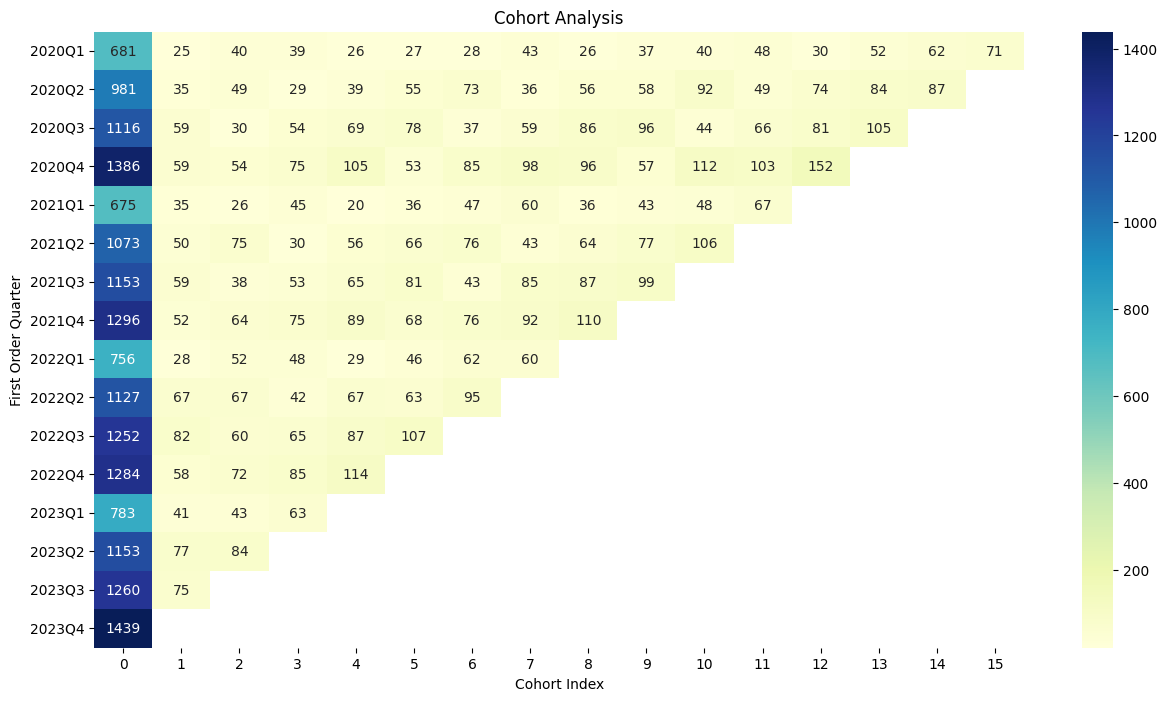

In [ ]:
plt.figure(figsize= (15,8))
sns.heatmap(data = df_cohort
            ,annot=True
            ,cmap='YlGnBu'
            ,fmt = 'g'
            )
plt.xlabel('Cohort Index')
plt.ylabel('First Order Quarter')
plt.title('Cohort Analysis')
plt.show()

In [ ]:
df_cohort_new = df_cohort

empty_column = pd.Series([0] * len(df_cohort_new), name='SLKH')

df_cohort_new.insert(loc=0, column='So lg KH', value=empty_column)

cohort_size_quarterly_new = df_cohort_new.iloc[:, 1]

retention_matrix_quarterly_new = df_cohort_new.divide(cohort_size_quarterly_new, axis=0)

retention_matrix_quarterly_new

quarter_diff,So lg KH,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
first_quarter,,,,,,,,,,,,,,,,,
2020Q1,NaN,1.0,0.036711,0.058737,0.057269,0.038179,0.039648,0.041116,0.063142,0.038179,0.054332,0.058737,0.070485,0.044053,0.076358,0.091043,0.104258
2020Q2,NaN,1.0,0.035678,0.049949,0.029562,0.039755,0.056065,0.074414,0.036697,0.057085,0.059123,0.093782,0.049949,0.075433,0.085627,0.088685,NaN
2020Q3,NaN,1.0,0.052867,0.026882,0.048387,0.061828,0.069892,0.033154,0.052867,0.077061,0.086022,0.039427,0.059140,0.072581,0.094086,NaN,NaN
2020Q4,NaN,1.0,0.042569,0.038961,0.054113,0.075758,0.038240,0.061328,0.070707,0.069264,0.041126,0.080808,0.074315,0.109668,NaN,NaN,NaN
2021Q1,NaN,1.0,0.051852,0.038519,0.066667,0.029630,0.053333,0.069630,0.088889,0.053333,0.063704,0.071111,0.099259,NaN,NaN,NaN,NaN
2021Q2,NaN,1.0,0.046598,0.069897,0.027959,0.052190,0.061510,0.070829,0.040075,0.059646,0.071761,0.098788,NaN,NaN,NaN,NaN,NaN
2021Q3,NaN,1.0,0.051171,0.032958,0.045967,0.056375,0.070252,0.037294,0.073721,0.075455,0.085863,NaN,NaN,NaN,NaN,NaN,NaN
2021Q4,NaN,1.0,0.040123,0.049383,0.057870,0.068673,0.052469,0.058642,0.070988,0.084877,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2022Q1,NaN,1.0,0.037037,0.068783,0.063492,0.038360,0.060847,0.082011,0.079365,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


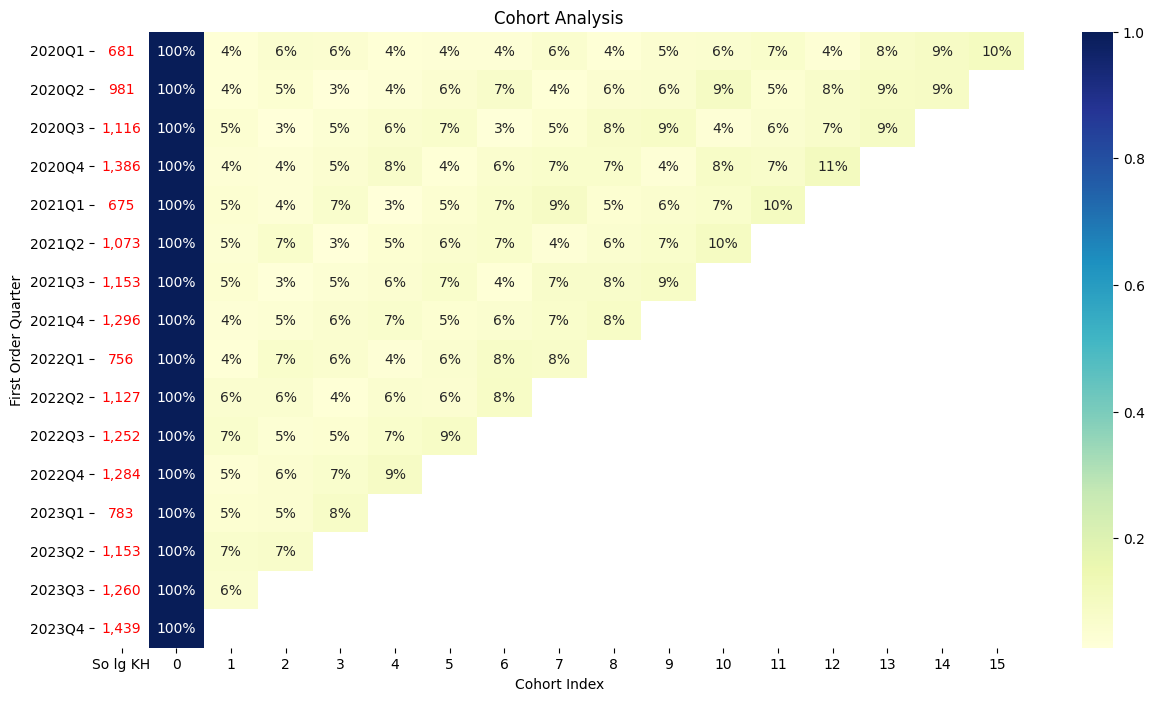

In [ ]:
plt.figure(figsize= (15,8))

sns.heatmap(data = retention_matrix_quarterly_new

            ,annot=True

            ,cmap='YlGnBu'

            ,fmt = '.0%')

for i in range(len(df_cohort)):

    plt.text(0.5, i + 0.5, '{:,.0f}'.format(df_cohort.iloc[i, 1])

            , ha='center'

            , va='center'

            , color = 'red')

plt.xlabel('Cohort Index')

plt.ylabel('First Order Quarter')

plt.title('Cohort Analysis')

plt.show()

**Nhận xét chi tiết sau khi áp dụng biểu đồ Cohort**

 **Đánh giá tổng quan về quý có tỉ lệ khách hàng mua hàng giữa các quý trong năm**

 **Quý có tỉ lệ KH quay trở lại cao nhất**
- Ta có thể thấy tỉ lệ khách hàng mua lại vào quý 4 hàng năm luôn là quý đứng đầu trong 4 quý về tỉ lệ khách hàng quay trở lại mua sản phẩm. Điều này có thể đến từ việc do quý 4 rơi vào những tháng cuối năm và có nhiều sự kiện lớn như Giáng Sinh, Tết Dương Lịch và chuẩn bị cho Tết Nguyên Đán.

- Do có nhiều sự kiến lớn nên các sàn TMĐT nắm bắt nhu cầu lớn của khách hàng nên đã đưa ra những chương trình khuyến mãi lớn nhằm kích cầu lượng mua sản phẩm của KH. Những chương trình săn sale điển hình như 10/10, 11/11, 12/12 với những sản phẩm được giảm giá sâu và nhiều voucher dẫn đến tâm lý KH quay trở lại mua sản phẩm cao.
 **Số lượng khách hàng mới**
- Bên cạnh tỉ lệ KH quay trở lại cao nhất thì quý 4 cũng có số lượng KH mới mua hàng cao nhất trong 4 quý. Điều này có thể khẳng định sức mua của các khách hàng sẽ đạt cao nhất vào quý 4.

- Số lượng khách hàng thấp nhất sẽ rơi vào quý 1 hàng năm điều này có thể lý giải do đây là quý diễn ra sau tết Nguyên Đán khi người tiêu dùng thường đã dồn phần lớn ngân sách để mua sắm và quà cáp vào cuối năm trước và trước dịp Tết Nguyên Đán. Điều này có thể lý giải khi sau Tết mọi người thường có xu hướng siết chặt chi tiêu để tích lũy lại sau khoảng thời gian đã chi nhiều tiền chuẩn bị cho các dịp lễ lớn.

 **Tỉ lệ Retention Rate (tỉ lệ giữ chân KH )**
Lấy một năm cụ thể để xét Retention Rate của các khách hàng là năm 2022 ra được tỉ lệ như sau
- Quý 1: tỉ lệ 4 - 7%
- Quý 2: tỉ lệ 5- 8%
- Quý 3: tỉ lệ 6-9%
- Quý 4: tỉ lệ 5-9%

Giống như ở trên đã phân tích về tỉ lệ khách hàng quay trở lại mua hàng thì vẫn là cao nhất là quý 4 và thấp nhất là quý 1. Tuy nhiên có thể thấy tỉ lệ quý 4 thấp hơn so với quý 2 và 3 là không quá lớn và đây có thể là dấu hiệu khiến cho Doanh Nghiệp có thêm niềm tin vào quý 1 sẽ là quý tiềm năng trong tương lai để phát triển thêm cả số lượng khách hàng quay trở lại mua hàng cũng như số lượng khách hàng mới

### **2.2.2. Retention Rate giữa nhóm Corporate và Consumer**

In [ ]:
# Lấy lại cột Segment cho mỗi CustomerID từ bảng df_merge
customer_segment = df_merge[['CustomerID', 'Segment']].drop_duplicates()
df_cohort_seg = df_prep_cohort.merge(customer_segment, on='CustomerID', how='left')

In [ ]:
df_cohort_seg = df_cohort_seg[df_cohort_seg['Segment'].isin(['Corporate', 'Consumer'])]
df_cohort_seg

,CustomerID,OrderDate,first_purchase_date,first_quarter,quarter_diff,Segment
0,TH-211151,2020-04-04,2020-04-04,2020Q2,0,Corporate
1,BD-116051,2021-09-01,2021-09-01,2021Q3,0,Consumer
2,TS-212051,2023-06-18,2023-06-18,2023Q2,0,Corporate
6,BG-110351,2021-09-28,2021-09-28,2021Q3,0,Consumer
7,SS-201401,2021-12-16,2021-12-16,2021Q4,0,Corporate
...,...,...,...,...,...,...
25714,LS-6945147,2022-02-02,2022-02-02,2022Q1,0,Corporate
25715,DB-3210147,2022-04-12,2022-04-12,2022Q2,0,Consumer
25716,EB-3870147,2022-05-09,2022-05-09,2022Q2,0,Consumer
25717,BT-1395147,2023-06-09,2023-06-09,2023Q2,0,Corporate


In [ ]:
# Đếm số lượng khách hàng duy nhất theo Segment, Quý đầu tiên và Khoảng cách quý
grouped_seg = df_cohort_seg.groupby(['Segment', 'first_quarter', 'quarter_diff'])['CustomerID'].nunique().reset_index()
grouped_seg

,Segment,first_quarter,quarter_diff,CustomerID
0,Consumer,2020Q1,0,376
1,Consumer,2020Q1,1,12
2,Consumer,2020Q1,2,22
3,Consumer,2020Q1,3,22
4,Consumer,2020Q1,4,15
...,...,...,...,...
267,Corporate,2023Q2,1,28
268,Corporate,2023Q2,2,25
269,Corporate,2023Q3,0,349
270,Corporate,2023Q3,1,13


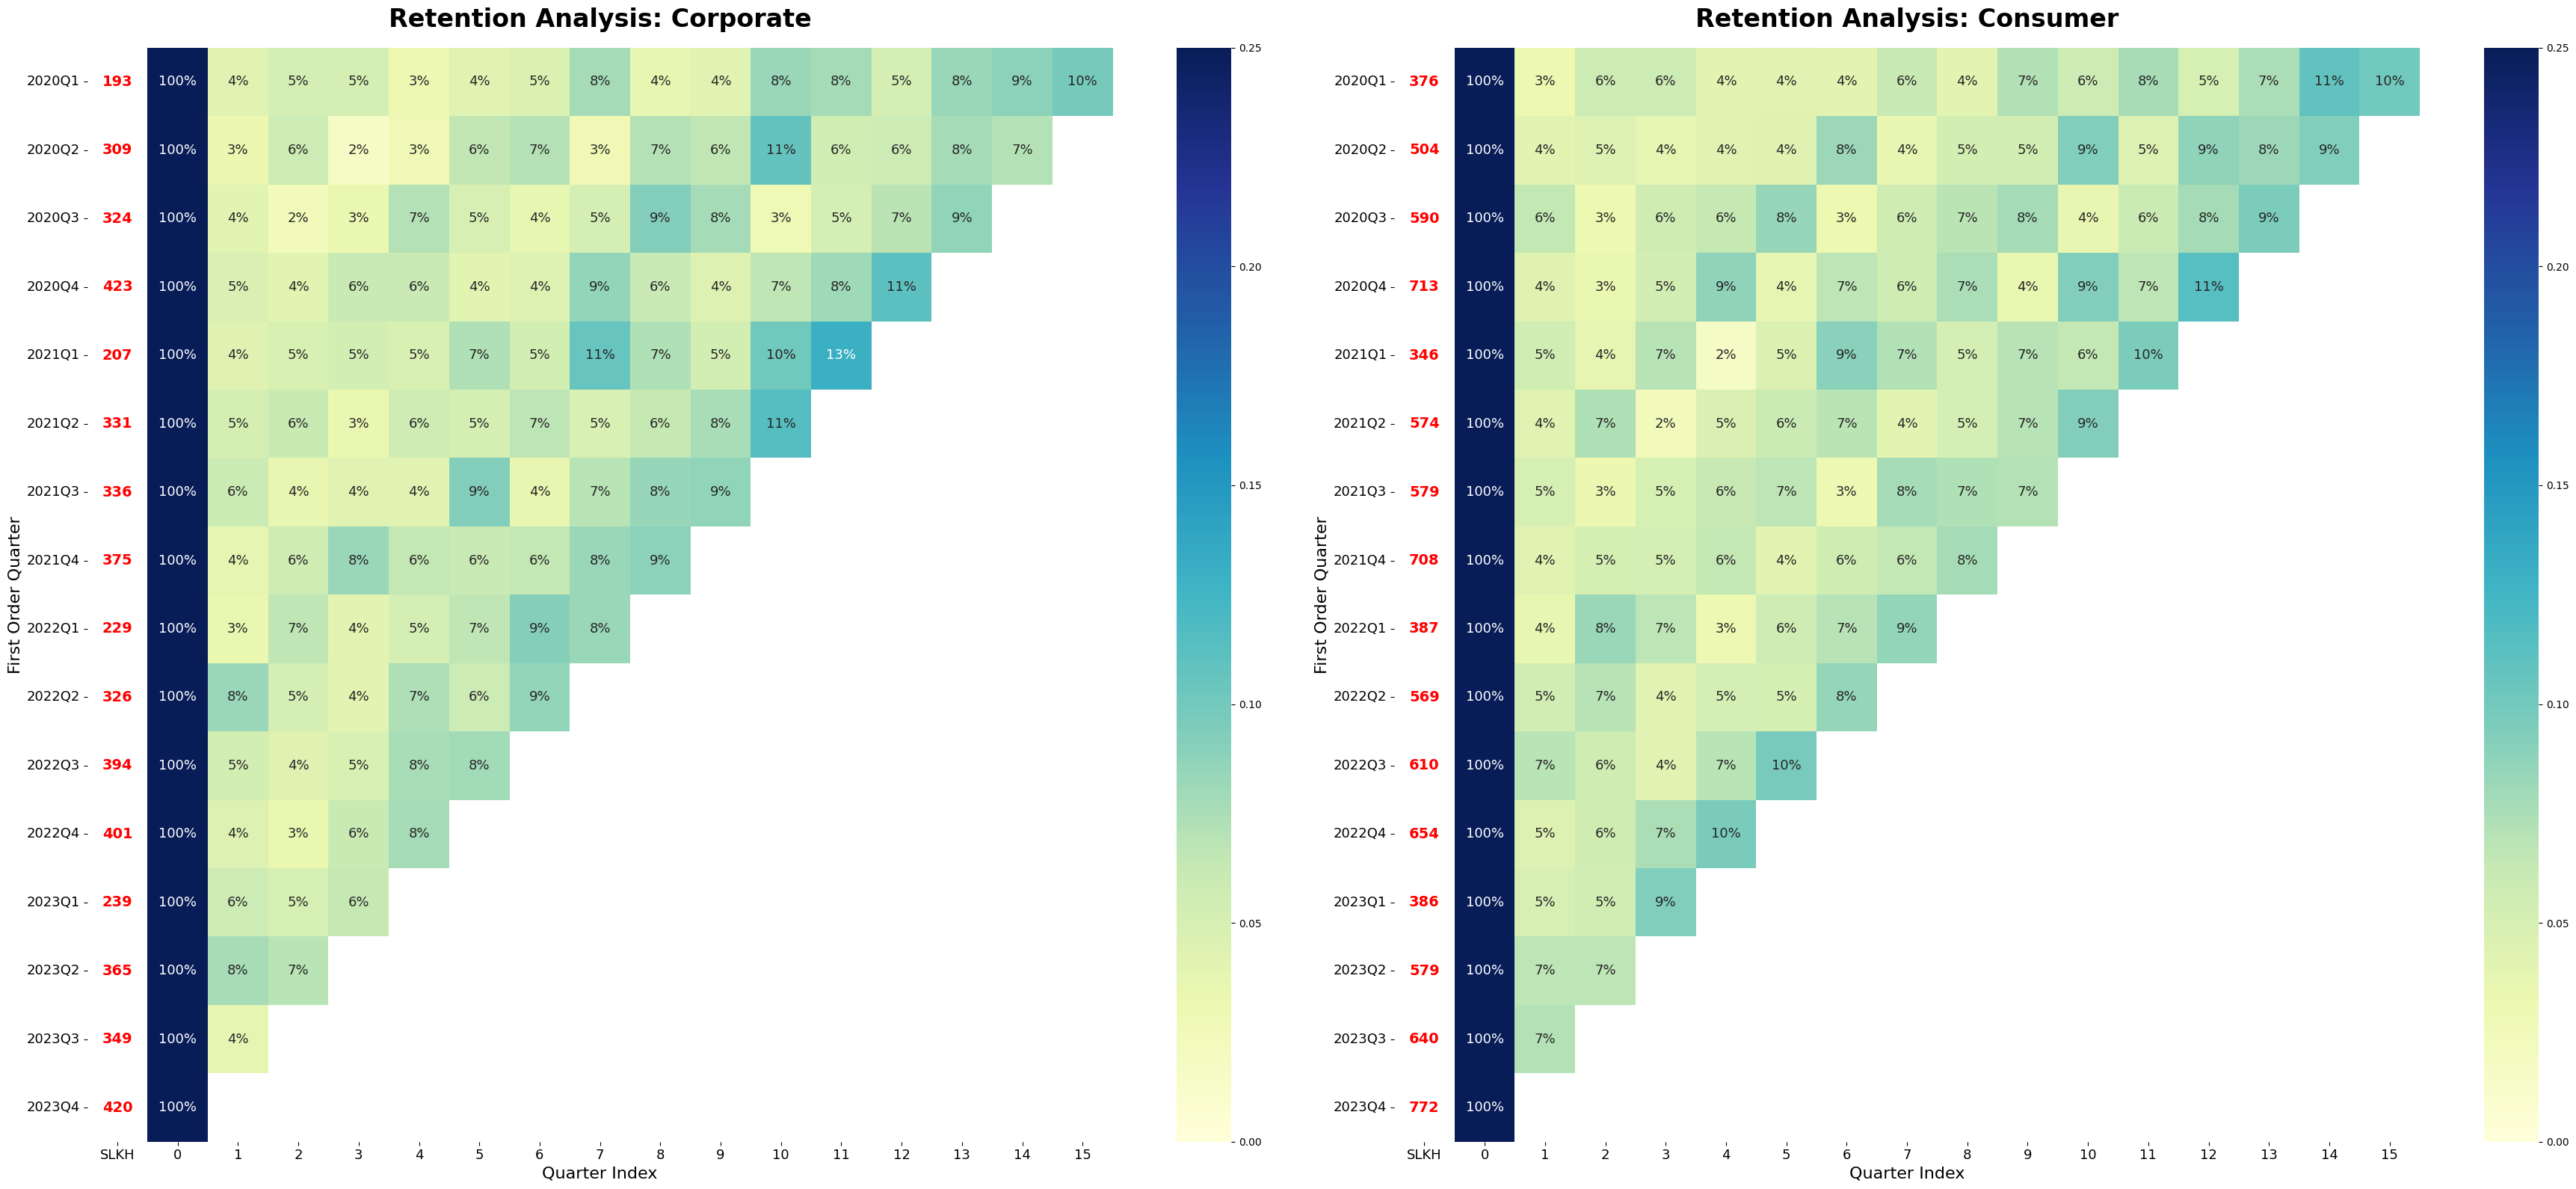

In [ ]:
# 1. Định nghĩa hàm chuẩn bị dữ liệu
def prep_retention_data(segment_name):
    df_seg = grouped_seg[grouped_seg['Segment'] == segment_name]
    pivot = df_seg.pivot(index='first_quarter', columns='quarter_diff', values='CustomerID')
    cohort_size = pivot.iloc[:, 0]
    retention = pivot.divide(cohort_size, axis=0)

    if 'SLKH' not in retention.columns:
        retention.insert(loc=0, column='SLKH', value=np.nan)

    return retention, cohort_size

# 2. Xử lý dữ liệu
corp_retention, corp_size = prep_retention_data('Corporate')
cons_retention, cons_size = prep_retention_data('Consumer')

# Chuyển index sang chuỗi để tránh lỗi hiển thị của PeriodIndex
corp_retention.index = corp_retention.index.astype(str)
cons_retention.index = cons_retention.index.astype(str)

# 3. Vẽ biểu đồ song song
fig, axes = plt.subplots(1, 2, figsize=(36, 16))

vmin, vmax = 0.0, 0.25

# --- BIỂU ĐỒ CORPORATE ---
sns.heatmap(
    corp_retention,
    annot=True,
    fmt='.0%',
    cmap='YlGnBu',
    ax=axes[0],
    vmin=vmin,
    vmax=vmax,
    annot_kws={'size': 13}
)

axes[0].set_title('Retention Analysis: Corporate', fontsize=24, fontweight='bold', pad=20)
axes[0].set_ylabel('First Order Quarter', fontsize=16)
axes[0].set_xlabel('Quarter Index', fontsize=16)
axes[0].tick_params(axis='y', labelrotation=0, labelsize=13)
axes[0].tick_params(axis='x', labelsize=13)

# Ghi số lượng khách hàng
for i in range(len(corp_size)):
    if not np.isnan(corp_size.iloc[i]):
        axes[0].text(
            0.5, i + 0.5, f"{int(corp_size.iloc[i])}",
            ha='center', va='center',
            color='red', fontweight='bold', fontsize=14
        )

# --- BIỂU ĐỒ CONSUMER ---
sns.heatmap(
    cons_retention,
    annot=True,
    fmt='.0%',
    cmap='YlGnBu',
    ax=axes[1],
    vmin=vmin,
    vmax=vmax,
    annot_kws={'size': 13}
)

axes[1].set_title('Retention Analysis: Consumer', fontsize=24, fontweight='bold', pad=20)
axes[1].set_ylabel('First Order Quarter', fontsize=16)
axes[1].set_xlabel('Quarter Index', fontsize=16)
axes[1].tick_params(axis='y', labelrotation=0, labelsize=13)
axes[1].tick_params(axis='x', labelsize=13)

# Ghi số lượng khách hàng
for i in range(len(cons_size)):
    if not np.isnan(cons_size.iloc[i]):
        axes[1].text(
            0.5, i + 0.5, f"{int(cons_size.iloc[i])}",
            ha='center', va='center',
            color='red', fontweight='bold', fontsize=14
        )

plt.tight_layout()
plt.show()

**Retention Rate của nhóm Consumer và Customer**

Phân tích Cohort Retention cho thấy cả hai phân khúc Corporate và Consumer đều có tỷ lệ khách hàng quay lại giảm dần sau quý mua hàng đầu tiên.
- Nhóm Consumer : Thể hiện tính biến động lớn khi dù có quy mô khách hàng lớn nhưng tỷ lệ giữ chân suy giảm nhanh chóng sau các quý đầu.

==> Hành vi của nhóm này chịu ảnh hưởng lớn bởi các chiến dịch khuyến mãi ngắn hạn, thiếu tính trung thành bền bỉ.

- Nhóm Corporate : Thể hiện độ bền vững cao hơn. Tỷ lệ Retention duy trì ổn định và giảm chậm qua các quý. Điều này cho thấy nhu cầu mua sắm nhóm này có tính chu kỳ và gắn kết lâu dài.

### 2.2.3. Tìm nhóm khách hàng có AnnualIncome mang lại lợi nhuận cao nhất


In [ ]:
# tạo biến
customer_frequency = ecom_sales.groupby('CustomerID')['OrderID'].nunique().reset_index()
customer_frequency.columns = ['CustomerID', 'Frequency']

In [ ]:
# Tạo bảng thống kê tần suất (Frequency Table)
# sort_index() giúp bảng hiển thị thứ tự mua 1 lần, 2 lần... từ bé đến lớn
freq_table = customer_frequency['Frequency'].value_counts().sort_index().reset_index()
freq_table.columns = ['Frequency', 'Customer_Count']

# Hiển thị bảng
freq_table

,Frequency,Customer_Count
0,1,11979
1,2,3467
2,3,1311
3,4,457
4,5,158
5,6,29
6,7,12
7,8,1
8,9,1


In [ ]:
# Tạo bảng thống kê tần suất (Frequency Table)
# sort_index() giúp bảng hiển thị thứ tự mua 1 lần, 2 lần... từ bé đến lớn
freq_table = customer_frequency['Frequency'].value_counts().sort_index().reset_index()
freq_table.columns = ['Frequency', 'Customer_Count']

# Hiển thị bảng
freq_table

,Frequency,Customer_Count
0,1,11979
1,2,3467
2,3,1311
3,4,457
4,5,158
5,6,29
6,7,12
7,8,1
8,9,1


In [ ]:
# Chia Frequency (từ 1 đến 9) thành 5 khoảng (bin)
# Khoảng cách mỗi bin sẽ là (9-1)/5 = 1.6
customer_frequency['F_score'] = pd.cut(customer_frequency['Frequency'], bins=5, labels=[1, 2, 3, 4, 5])

# Chuyển sang kiểu int
customer_frequency['F_score'] = customer_frequency['F_score'].astype(int)

# Tạo bảng đối chiếu để kiểm tra khoảng giá trị
df_F_score = customer_frequency[['Frequency', 'F_score']].drop_duplicates().sort_values(by='Frequency').reset_index(drop=True)
df_F_score

,Frequency,F_score
0,1,1
1,2,1
2,3,2
3,4,2
4,5,3
5,6,4
6,7,4
7,8,5
8,9,5


Thu nhập trung bình theo từng nhóm F_score:
   F_score  AnnualIncome
0        1  57317.104752
1        2  56300.904977
2        3  57025.316456
3        4  48536.585366
4        5  60000.000000


/tmp/ipykernel_770/3107820148.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='F_score', y='AnnualIncome', data=income_by_f_score, palette='viridis')


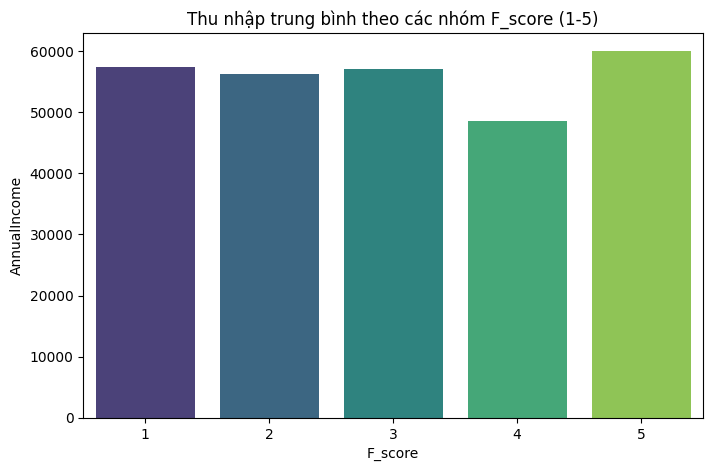

,F_score,AnnualIncome,Frequency
0,1,57317.104752,1.224459
1,2,56300.904977,3.258484
2,3,57025.316456,5.000000
3,4,48536.585366,6.292683
4,5,60000.000000,8.500000


In [ ]:
# 1. Merge dữ liệu để lấy AnnualIncome của từng khách hàng
# 'customer_frequency' hiện đã có cột F_score
# Sửa 'customers' thành 'customer'
df_result = pd.merge(customer_frequency, customer[['CustomerID', 'AnnualIncome']], on='CustomerID', how='left')

# 2. Tính thu nhập trung bình (mean) theo từng F_score
income_by_f_score = df_result.groupby('F_score')['AnnualIncome'].mean().reset_index()

# 3. Hiển thị kết quả
print("Thu nhập trung bình theo từng nhóm F_score:")
print(income_by_f_score)

# 4. Trực quan hóa để dễ nhìn xu hướng
plt.figure(figsize=(8, 5))
sns.barplot(x='F_score', y='AnnualIncome', data=income_by_f_score, palette='viridis')
plt.title('Thu nhập trung bình theo các nhóm F_score (1-5)')
plt.show()

# 5. Tần suất mua hàng theo từng nhóm
analysis_by_f_score = df_result.groupby('F_score')[['AnnualIncome', 'Frequency']].mean().reset_index()
analysis_by_f_score

**Nhận xét**
- Nhóm khách hàng F1,2,3,5 có mức thu nhập trung bình khá đồng đều khi nằm trong khoảng từ 50.000 - 60.000 và chỉ có nhóm khách hàng F4 có thu nhập trung bình thấp hơn hẳn với mức thu nhập chưa đến 40.000
- Nhóm F4 dù có mức thu nhập thấp nhất nhưng đổi lại họ là nhóm khách hàng mua hàng với tần suất cao thứ 2 chỉ sau nhóm F5. Điều này chứng tỏ thu nhập trung bình không phản ánh hết tần suất mua hàng của khách hàng.
- Nhóm F5 (Nhóm khách hàng trung thành nhất): Đây là nhóm có mức thu nhập cao nhất (đạt mức tối đa ~60.000). Điều này cho thấy khách hàng nhóm này vừa có khả năng tài chính tốt lại vừa có tần suất mua hàng cao nhất.


Lợi nhuận trung bình theo từng nhóm F_score:
   F_score     Profit
0        1  19.668372
1        2  23.134465
2        3  27.040213
3        4  27.435098
4        5  57.760000


/tmp/ipykernel_770/2924194098.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='F_score', y='Profit', data=avg_profit_by_f, palette='viridis')


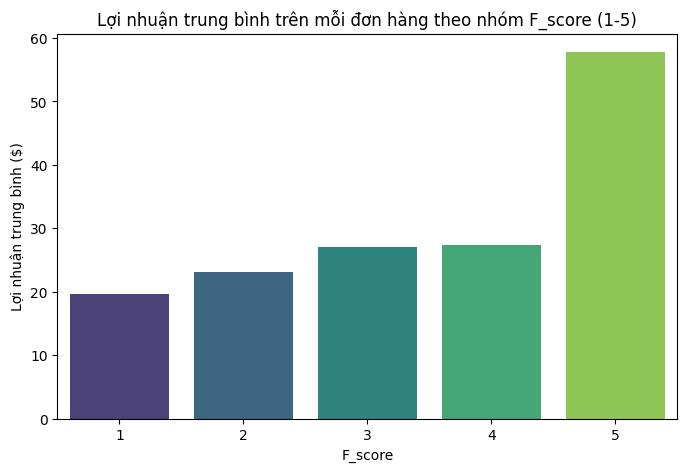

In [ ]:
# 1. Lấy thông tin Profit từ ecomsales và merge vào df_result
# Giả định df_result hiện tại chỉ đang có CustomerID và F_score
df_result = pd.merge(df_result, ecom_sales[['CustomerID', 'Profit']], on='CustomerID', how='left')

# 2. Bây giờ bạn mới thực hiện tính toán trung bình được
avg_profit_by_f = df_result.groupby('F_score', observed=True)['Profit'].mean().reset_index()

# 3. Hiển thị kết quả
print("Lợi nhuận trung bình theo từng nhóm F_score:")
print(avg_profit_by_f)

# 4. Trực quan hóa
plt.figure(figsize=(8, 5))
sns.barplot(x='F_score', y='Profit', data=avg_profit_by_f, palette='viridis')
plt.title('Lợi nhuận trung bình trên mỗi đơn hàng theo nhóm F_score (1-5)')
plt.ylabel('Lợi nhuận trung bình ($)')
plt.show()

**Nhận xét**

-  Biểu đồ cho thấy một xu hướng rất rõ ràng: Lợi nhuận trung bình trên mỗi đơn hàng đều tỉ lệ thuận theo từng nhóm F_score (tần suất mua hàng).

- Nhóm F1 (Tần suất thấp nhất): Lợi nhuận trung bình ở mức thấp nhất, gần ngưỡng 20 đơn vị tiền tệ. Điều này phản ánh nhóm khách hàng mới hoặc khách hàng vãng lai, có thể họ mua các sản phẩm giá trị thấp hoặc hưởng nhiều chiết khấu (discount).

- Nhóm F5 (Nhóm trung thành nhất): Lợi nhuận trung bình đạt mức cao nhất, xấp xỉ 60 đơn vị tiền tệ. Đây là minh chứng cho thấy tần suất mua hàng cao đi đôi với giá trị lợi nhuận mang lại cao.

# **3. Conclusion and Recommendation**
**Conclusion**
- Qua phân tích về số lượng khách hàng và tỉ lệ khách hàng quay trở lại giữa các quý ở trên có thể thấy doanh nghiệp đang là doanh nghiệp tích lũy, tận dụng tốt các quý giữa và cuối năm để thu hút khách mới.
- Đối với quý đầu tiên trong năm, mặc dù số lượng khách mới thấp nhưng nếu nhìn vào bảng retention_matrix_quarterly_new,ta có thể thấy tỷ lệ giữ chân khách hàng (Retention) của nhóm khách hàng mua lần đầu vào Q1 không hề tệ. Điều này có nghĩa là những người mua vào Q1 là nhóm "khách hàng thực sự có nhu cầu" chứ không phải bị thu hút bởi các đợt giảm giá ảo.

**Recommnendation**
- Đẩy mạnh thêm các chương trình dành cho quý đầu tiên trong năm như tạo thêm nhiều chương trình khuyến mãi và tung ra thêm những combo sản phẩm hoặc bộ sư tập sản phẩm mới để kích cầu sức mua của khách hàng

- Tập trung vào việc chăm sóc khách hàng cũ và có sức mua mạnh như nhóm Q2,Q3 và đặc biệt là nhóm Q4 nên tập trung vào các chiến lược Remarketing và tặng thêm các voucher với mục đích họ tiếp tục quay lại mua sản phẩm